# `stochastics.physics` — particle interactions lab

A classical many-body simulator built as a small, tested package:

| layer | what it does |
|---|---|
| `ParticleSystem` | structure-of-arrays state; `particles[0]` is a live, editable particle; explicit clusters |
| `Environment` | force **law** (gravity, Coulomb, any pairwise kernel) + **rules** (collisions, mergers, drag, clocks) + background **expansion** |
| `simulate` | velocity-Verlet time loop with continuous (swept-sphere) collision detection |
| energy ledger | `kinetic + potential + internal + radiated + dissipated + binding + expansion + drive` is conserved, so every run audits itself |
| `report` / `animate_2d` / `animate_3d` | one-call dashboard and animations |

The design rule that makes it safe to experiment: **policies decide, mechanics conserve.** A collision policy
only says *merge*, *bounce with restitution e* or *pass*; the mechanics execute it while conserving mass,
charge, momentum and constituents and booking every unit of energy.

*All quantities are dimensionless; this is a classical toy model, not a validated astrophysics or plasma code.*

In [1]:
import numpy as np
import pandas as pd
from dataclasses import replace

import stochastics
from stochastics import physics
from stochastics.physics import *

print('stochastics', stochastics.__version__)

stochastics 0.3.0


## 1. Particles

Two rotating clusters in 3D. `orbital_G` gives each member an approximately circular orbital speed about its
cluster centre (for the gravity constant it will feel), `velocity` sets the bulk drift, and `rotation` the
spin axis / sense. Masses, radii, charges, spins and polarities come from the `astro` preset.

In [2]:
G = 1e-4
astro_cfg = replace(PRESETS['astro'], radius_mean=0.003, radius_std=0.0008, velocity_std=0.03)

particles = ParticleSystem.random(
    n=400, preset=astro_cfg, seed=210, dimension=3,
    clusters=[
        Cluster(mean=[-3.5, -1.0, 0.0], std=[1.0, 1.0, 0.15], orbital_G=G, rotation=+1,
                velocity=[0.2, 0.12, 0.0]),
        Cluster(mean=[3.5, 1.0, 0.3], std=[0.8, 0.8, 0.12], orbital_G=G, rotation=[0.4, 0, -1],
                weight=0.8, velocity=[-0.2, -0.12, 0.0]),
    ])
particles

ParticleSystem(live=400, slots=400, dimension=3, t=0, clusters=2, constituents=('+', '-'))

Every particle is addressable as an object. `particles[0]` is a *live view*: assigning `particles[0].mass = ...`
writes straight into the arrays. `composition` counts its sub-particles per constituent type — this is what
drives the collision outcome later.

In [3]:
particles[0]

Particle(id=0, species='astro', mass=96.02, charge=0, radius=0.002513, spin=0, polarity=1, polarity_now=1, energy=0, position=[-3.789, -0.3296, 0.02234], velocity=[-0.5059, -0.2057, -0.0127], composition={+:4, -:2}, cluster_id=0, active=True)

Counts by cluster: {0: 221, 1: 179}


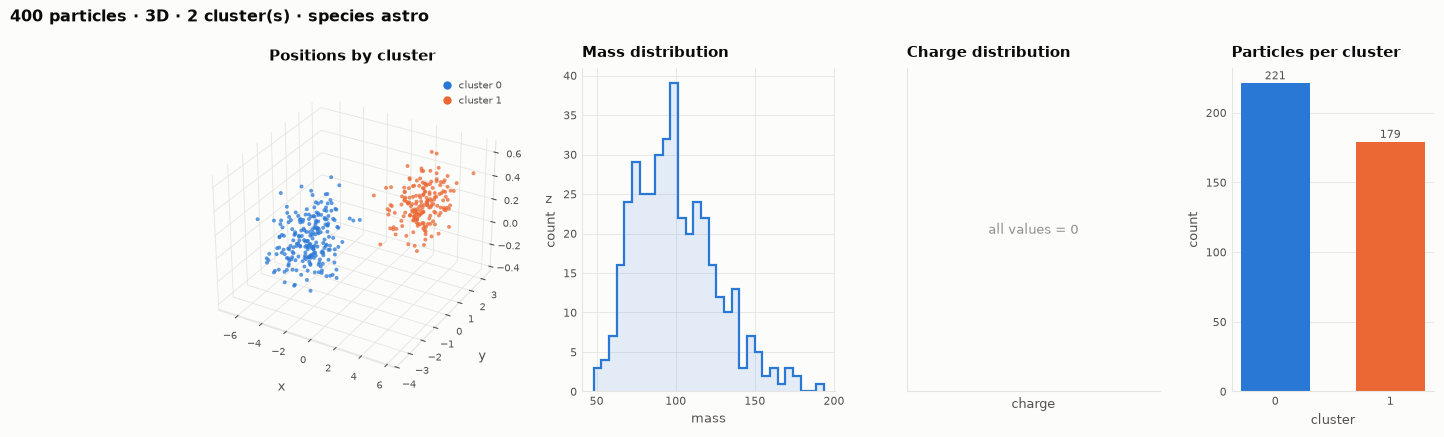

,count,mass_total,mass_mean,charge_mean,speed_mean,x_mean,y_mean,z_mean
cluster_id,,,,,,,,
0,221,22147.366092,100.214326,0.0,0.877007,-3.493008,-0.967875,-0.007956
1,179,17858.916148,99.770481,0.0,0.870537,3.416926,1.138674,0.299843


In [4]:
plot_initial(particles)
particles.describe()

## 2. Environment and run

The environment bundles the law, the rules and background conditions. Here: softened Newtonian gravity plus
radius-based collisions whose outcome is decided by the particles' composition.

In [5]:
env = Environment(law=Gravity(G=G, softening=0.12),
                  rules=[Collisions(CompositionAffinity())])
result = simulate(particles, env, steps=3200, dt=0.01, record_every=20)
result

SimulationResult(frames=161, t=0->32, live=400->345, events=156, dimension=3)

## 3. Report

`report(result)` = summary table + a 12-panel dashboard: trajectories, initial clusters, mass / charge /
speed distributions (initial vs final), active particles, cumulative events by type, the full energy ledger,
the relative energy residual, speed over time, velocity dispersion per cluster, and conservation drift.

,value
metric,
simulated time,0 -> 32
steps x dt,3200 x 0.01
runtime,28.38 s
particles (live),400 -> 345
events: inelastic,101
events: merge,55
mass drift,+7.276e-12
charge drift,+0.000e+00
momentum drift |dp|,3.765e-12 (scale 3.49e+04)


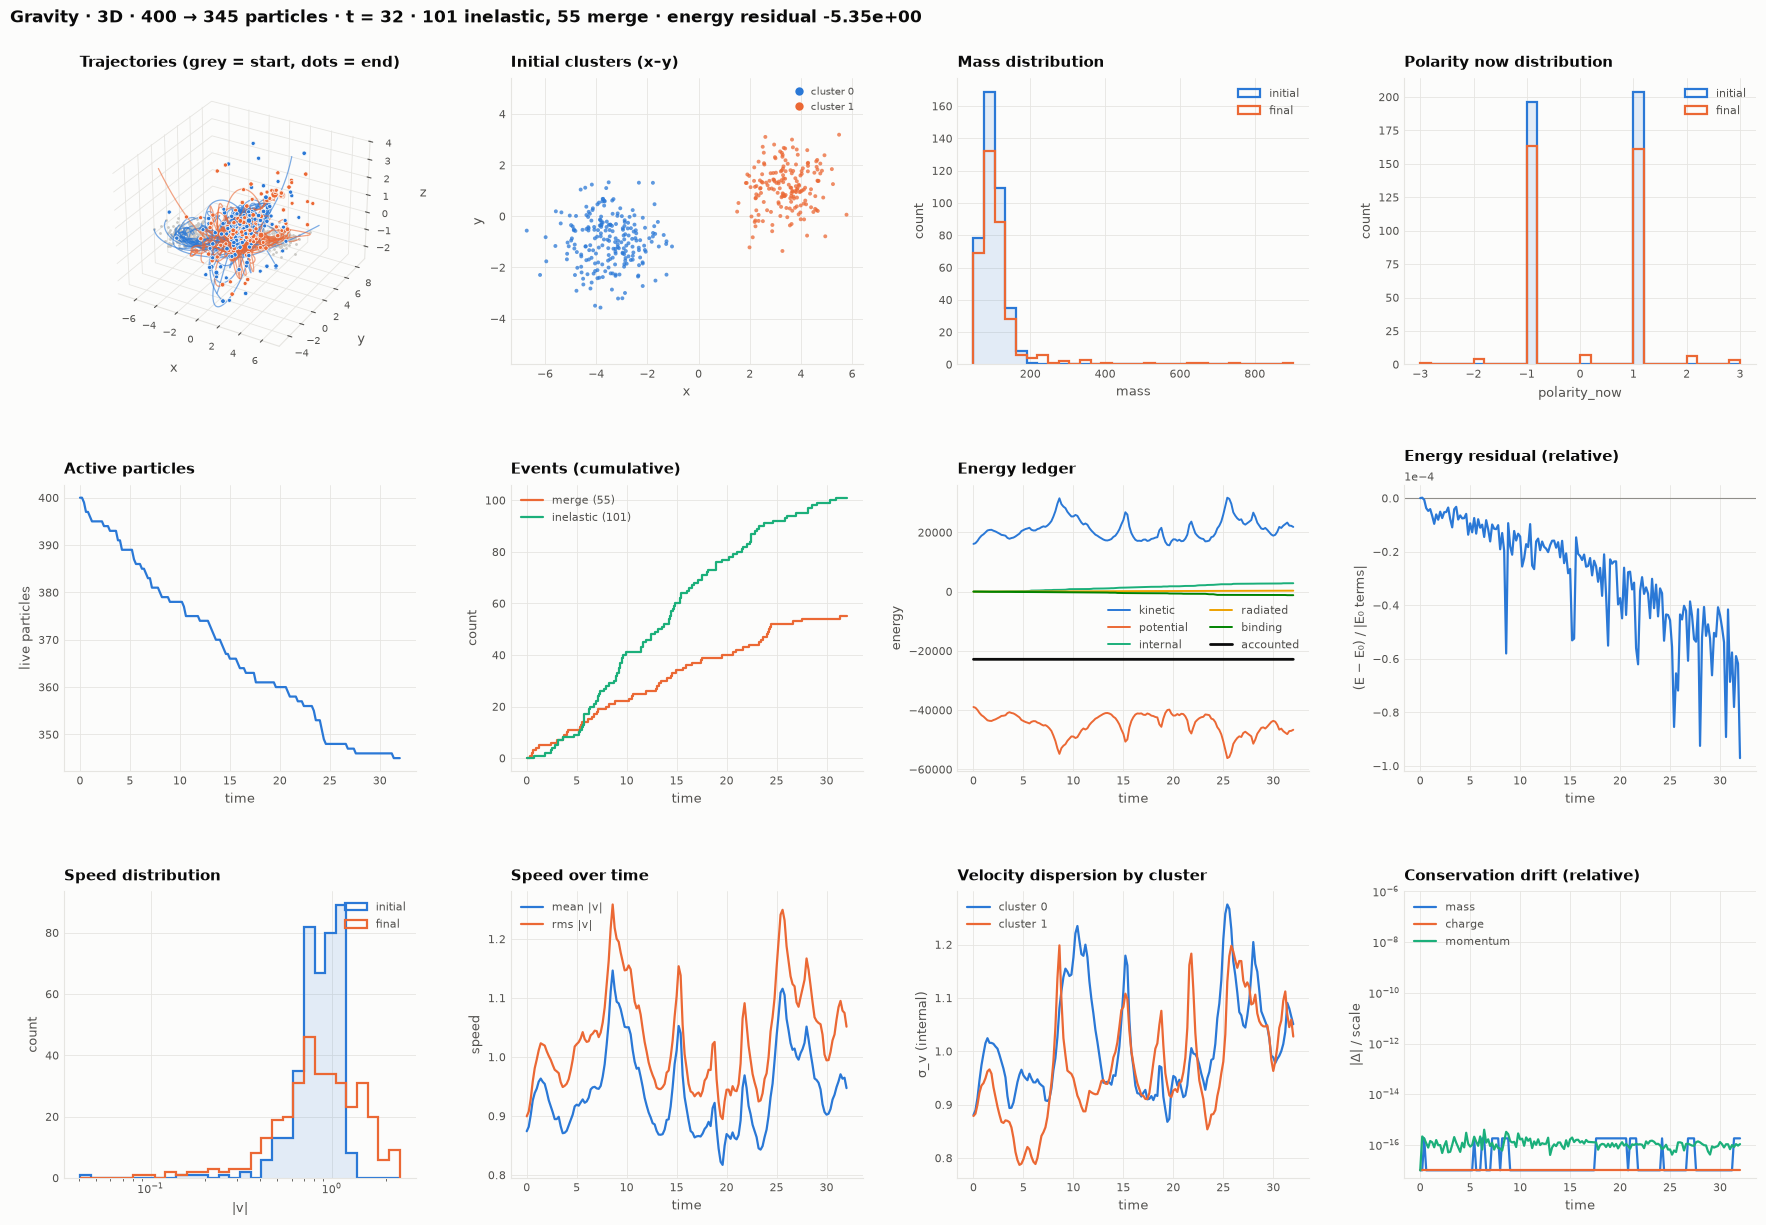

In [6]:
report(result)

## 4. Animations

Both work on the same result; `animate_2d` projects a 3D run onto a plane (`plane='xz'` etc.).
`color_by` accepts `'cluster'`, `'charge'`, `'polarity_now'`, `'mass'` or `'species'`; `trail=N` draws the
last N frames of each path; `save='run.gif'` writes a file.

In [7]:
animate_2d(result, max_frames=80, trail=6)

In [8]:
animate_3d(result, max_frames=80)

## 5. Collisions: a gradient driven by composition

Each particle is made of sub-particles. With constituent types `+` and `−` (opposites attract, likes repel),
take particle A = **3 `+` and 2 `−`**. Against a partner B, some of A's parts are attracted to B's parts and
some are repelled, while A's own parts hold A together. `CompositionAffinity` turns that into one number and
an outcome:

1. **affinity** `w = (c_A · K · c_B) / (n_A n_B)` ∈ [−1, 1] — the average pull between A's parts and B's parts;
2. **restitution** `e = e_min + (e_max − e_min)(1 − w)/2` — repulsive interiors bounce elastically, attractive ones stick;
3. after a bounce with `e` the pair keeps relative kinetic energy `K' = K_rel − (1 − e²)·½μv_n²`;
4. **binding** at contact `B = −U_law(A, B) + w·½μ·bond_speed²` — long-range law (gravity, Coulomb) plus short-range part bonds;
5. `K' < B` → **merge** (captured), otherwise **bounce** with `e` (elastic if `e = 1`, inelastic otherwise).

Heat from inelastic contacts goes into the particles' internal `energy`, minus a radiated fraction.

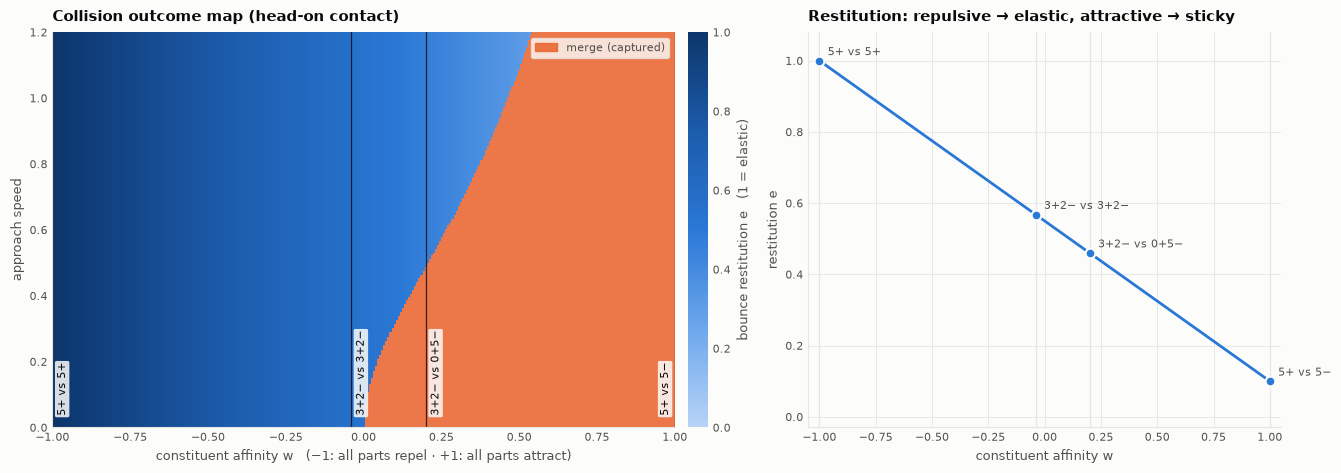

In [9]:
policy = CompositionAffinity()
plot_collision_regimes(policy, max_speed=1.2, examples=[
    ('5+ vs 5+', (5, 0), (5, 0)),
    ('3+2− vs 3+2−', (3, 2), (3, 2)),
    ('3+2− vs 0+5−', (3, 2), (0, 5)),
    ('5+ vs 5−', (5, 0), (0, 5)),
])

The same thing measured in the engine: head-on collisions of two unit masses (no long-range force), for a
grid of compositions and approach speeds.

In [10]:
def head_on(comp_a, comp_b, speed):
    pair = ParticleSystem.from_particles([
        Particle(mass=1, position=[-0.5, 0, 0], velocity=[speed / 2, 0, 0], radius=0.1, composition=comp_a),
        Particle(mass=1, position=[0.5, 0, 0], velocity=[-speed / 2, 0, 0], radius=0.1, composition=comp_b)])
    r = simulate(pair, law=NoForce(), rules=[Collisions(policy)], steps=int(1.5 / speed / 0.01) + 50, dt=0.01)
    ev = r.events.iloc[0]
    return {'A': comp_a, 'B': comp_b, 'speed': speed, 'outcome': ev.event,
            'affinity w': round(ev.affinity, 3), 'restitution': round(ev.restitution, 3),
            'heat': round(ev.heat, 4), 'energy residual': r.diagnostics.accounted_energy.iloc[-1] - r.diagnostics.accounted_energy.iloc[0]}

pairs = [((5, 0), (5, 0)), ((3, 2), (3, 2)), ((3, 2), (1, 4)), ((3, 2), (0, 5)), ((5, 0), (0, 5))]
pd.DataFrame([head_on(a, b, s) for a, b in pairs for s in (0.2, 0.8)])

,A,B,speed,outcome,affinity w,restitution,heat,energy residual
0,"(5, 0)","(5, 0)",0.2,elastic,-1.00,1.000,0.0000,0.000000e+00
1,"(5, 0)","(5, 0)",0.8,elastic,-1.00,1.000,0.0000,0.000000e+00
2,"(3, 2)","(3, 2)",0.2,inelastic,-0.04,0.568,0.0068,0.000000e+00
3,"(3, 2)","(3, 2)",0.8,inelastic,-0.04,0.568,0.1084,0.000000e+00
4,"(3, 2)","(1, 4)",0.2,merge,0.12,0.496,0.0100,0.000000e+00
5,"(3, 2)","(1, 4)",0.8,inelastic,0.12,0.496,0.1206,2.775558e-17
6,"(3, 2)","(0, 5)",0.2,merge,0.20,0.460,0.0100,0.000000e+00
7,"(3, 2)","(0, 5)",0.8,inelastic,0.20,0.460,0.1261,-2.775558e-17
8,"(5, 0)","(0, 5)",0.2,merge,1.00,0.100,0.0100,0.000000e+00
9,"(5, 0)","(0, 5)",0.8,merge,1.00,0.100,0.1600,0.000000e+00


## 6. Electromagnetic plasma in 3D

Charged particles from the `em` preset under Coulomb's law with composition collisions. Opposite charges
pull together and, because a particle's charge also biases what it is made of, they tend to stick on
contact (recombination): the mean |charge| of the survivors falls. Like charges are pushed apart and
bounce. Colour = charge.

,value
metric,
simulated time,0 -> 10
steps x dt,2000 x 0.005
runtime,9.07 s
particles (live),300 -> 229
events: merge,71
events: inelastic,57
events: elastic,2
mass drift,-1.137e-13
charge drift,+0.000e+00


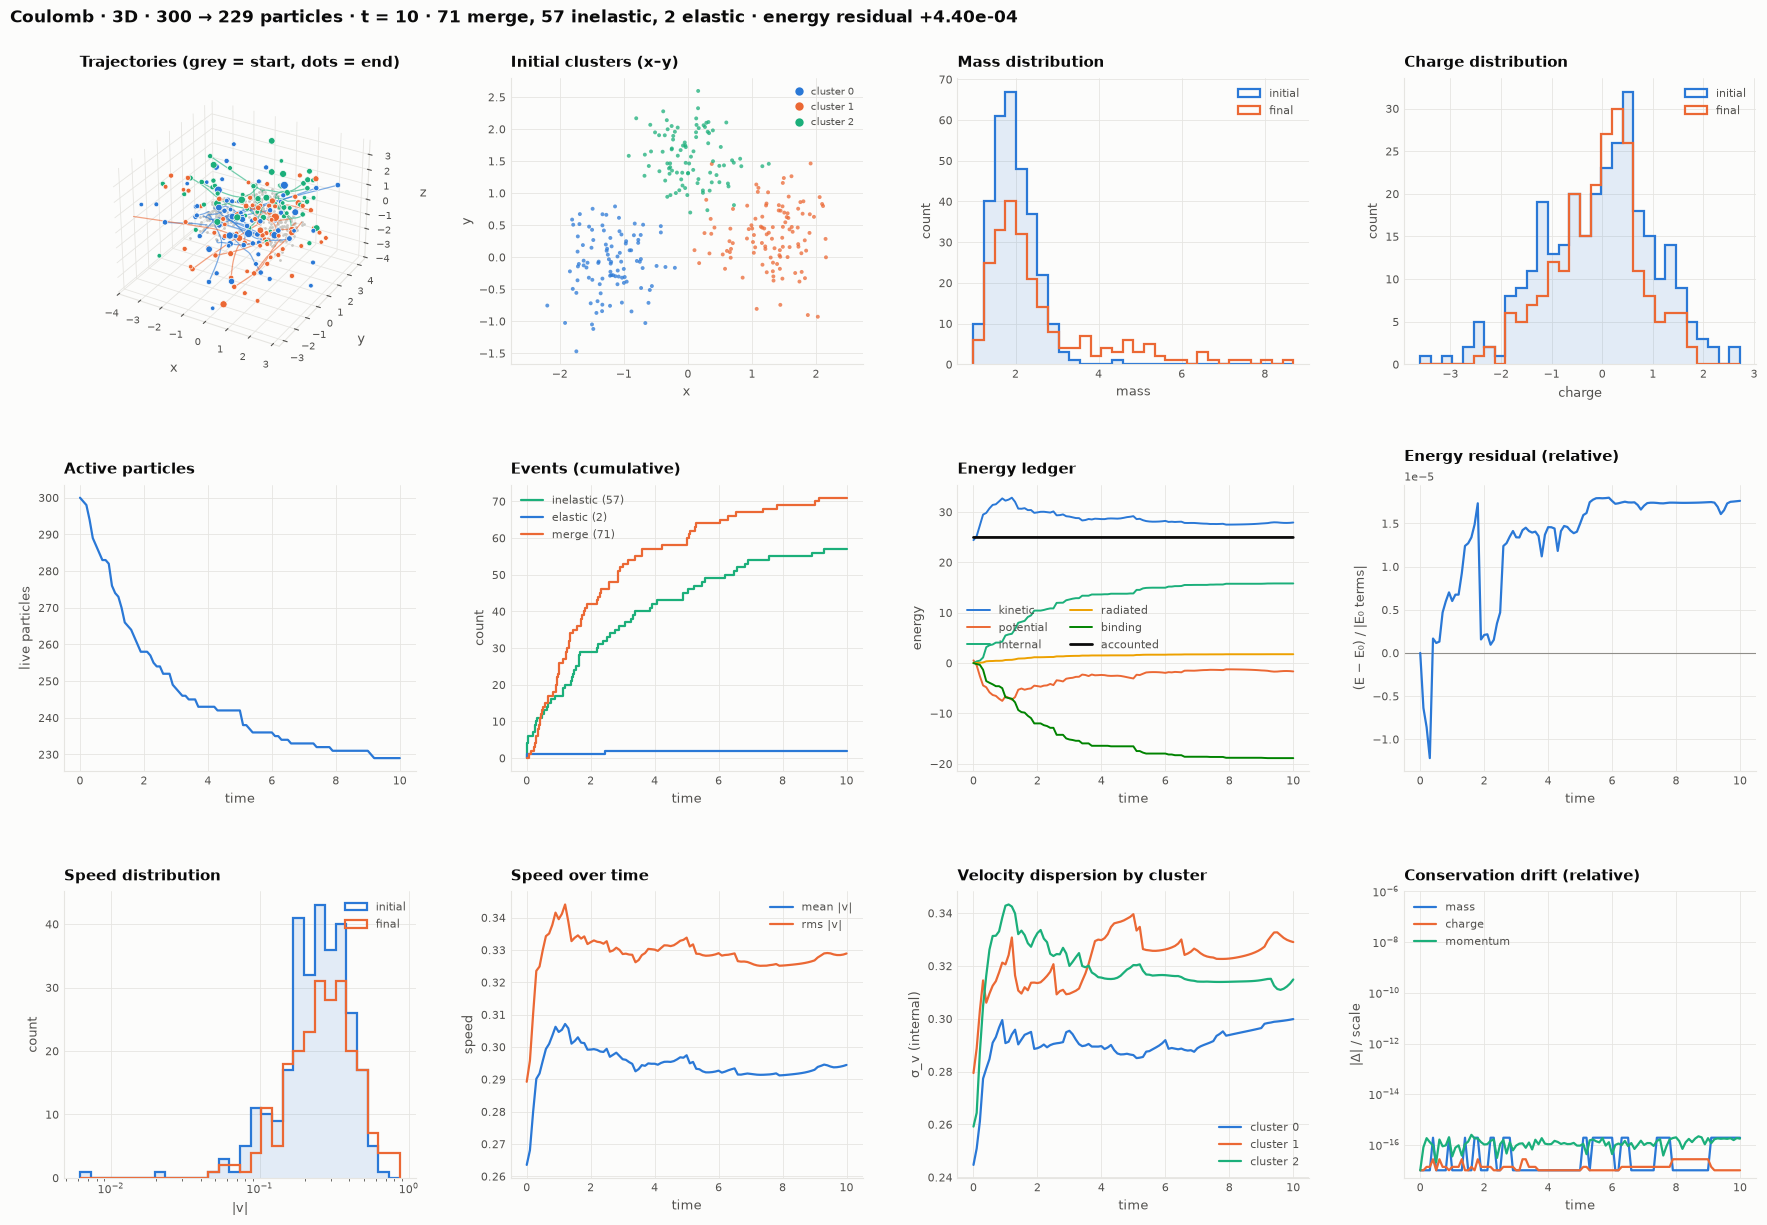

mean |charge|: 0.869 -> 0.653


In [11]:
em_cfg = replace(PRESETS['em'], radius_mean=0.04, radius_std=0.01)
plasma = ParticleSystem.random(
    n=300, preset=em_cfg, seed=21, dimension=3,
    clusters=[Cluster(mean=[-1.2, 0, 0], std=0.5, velocity=[0.15, 0, 0]),
              Cluster(mean=[1.2, 0.3, 0], std=0.5, velocity=[-0.15, 0, 0]),
              Cluster(mean=[0, 1.5, 0.5], std=0.4)])
env_em = Environment(law=Coulomb(k=0.02, softening=0.05),
                     rules=[Collisions(CompositionAffinity(bond_speed=0.3))])
result_em = simulate(plasma, env_em, steps=2000, dt=0.005, record_every=20)
report(result_em)
first, last = (result_em.history[result_em.history.time == t] for t in result_em.diagnostics.time.iloc[[0, -1]])
print(f'mean |charge|: {first.charge.abs().mean():.3f} -> {last.charge.abs().mean():.3f}')

In [12]:
animate_3d(result_em, max_frames=80, color_by='charge')

## 7. Validation

Each run audits itself. The table below collects the invariants from the runs above; `pytest` in the repo
root checks these and more (force = −∇U, Coulomb/gravity against an independent reference implementation,
policy equivalence, swept-sphere detection, emission conservation, second-order convergence of the residual).

In [13]:
def invariants(name, r):
    d = r.diagnostics
    first = r.history[r.history.time == d.time.iloc[0]]
    p = np.stack([d[f'p_{c}'] for c in 'xyz'[:r.dimension]], axis=1)
    scale = abs(d.kinetic.iloc[0]) + abs(d.potential.iloc[0]) + abs(d.internal.iloc[0])
    return {'run': name, 'events': len(r.events),
            'mass drift': abs(d.mass.iloc[-1] - d.mass.iloc[0]) / d.mass.iloc[0],
            'charge drift': abs(d.charge.iloc[-1] - d.charge.iloc[0]),
            'momentum drift': np.linalg.norm(p[-1] - p[0]) / (first.mass * first.speed).sum(),
            'energy residual (rel.)': (d.accounted_energy.iloc[-1] - d.accounted_energy.iloc[0]) / scale}

pd.DataFrame([invariants('galaxies', result), invariants('plasma', result_em)]).set_index('run')

,events,mass drift,charge drift,momentum drift,energy residual (rel.)
run,,,,,
galaxies,156,1.818704e-16,0.0,1.079393e-16,-0.000097
plasma,130,1.927754e-16,0.0,1.767484e-16,0.000018


## 8. Background expansion (toy)

`SpaceExpansion(rate=H)` stretches separations by `exp(H·dt)` per step (velocities are peculiar). Without
forces, every separation grows exactly as `d(t) = d₀·e^{Ht}`; with gravity, the potential-energy change it
causes is booked in the `expansion` ledger.

In [14]:
astro_exp = replace(PRESETS['astro'], expansion_rate=0.2)
world_exp = ParticleSystem.random(n=50, preset=astro_exp, seed=210, dimension=3)
world_exp.velocity[:] = 0.0
d0 = np.linalg.norm(world_exp.position[0] - world_exp.position[1])
result_exp = simulate(world_exp, law=NoForce(), steps=1000, dt=0.01, record_every=10,
                      expansion=SpaceExpansion(rate=astro_exp.expansion_rate))
T = result_exp.diagnostics.time.iloc[-1]
d1 = np.linalg.norm(world_exp.position[0] - world_exp.position[1])
print(f'separation {d0:.4f} -> {d1:.4f}; expected d0*exp(H*T) = {d0 * np.exp(astro_exp.expansion_rate * T):.4f}')

separation 6.1644 -> 45.5494; expected d0*exp(H*T) = 45.5494
